# 05 – Rarefied entropy and length control (H1 machinery)

**Why this notebook exists.** Plain frame entropy depends on how many frame hits a text has: few hits give a low entropy by arithmetic, not by emphasis. Chatbot answers have about 16–26 hits and 300-word news chunks about 8, so a plain comparison would favour the chatbots for the wrong reason. Here every text is compared at the **same number of hits** (rarefaction), and lengths are matched to each chatbot's own length distribution.

**Rarefied normalised entropy.** Draw K frame hits at random *without replacement* from a text's hits, compute the normalised Shannon entropy (÷ log 6) of the K draws, repeat 1,000 times and average. K = 5 is the main setting; 3 and 8 are sensitivity checks. A text with fewer than K hits cannot be rarefied: it is excluded, and *how many* are excluded is itself a result (frame density).
Note the ceiling: 5 draws can occupy at most 5 of 6 frames, so the maximum is log 5 / log 6 = 0.898, not 1. Compare groups at the same K only.

**The gate.** The sections that *compare groups on H1* (main comparison, bounds, sensitivity, pooled) are written and tested on label-shuffled data, but switched off (`H_TESTS_ENABLED = False`) until the lexicon is signed off (see `07_lexicon_signoff.ipynb`). Everything before that gate is measurement: densities, lengths, correlations, per-text scores.

**Clusters.** Answers to the same question are not independent (18 questions, 6 answers each per chatbot), and neither are articles from one outlet. Intervals use a cluster bootstrap: `question_id` for chatbots, `outlet` for news.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, ks_2samp

from framescore import Lexicon, find_hits, count_vector, entropy, rarefied_entropy, MAX_WORDS

H_TESTS_ENABLED = False        # flip to True only after the lexicon is signed off (07_lexicon_signoff.ipynb)
SEED, REPS, KS = 42, 1000, (3, 5, 8)
MAIN_K = 5

CFG = json.load(open("config.json"))
OUT = Path(CFG["analysis_dir"]); OUT.mkdir(parents=True, exist_ok=True)
LEX = Lexicon(CFG["lexicon_json"]); FRAMES = LEX.frames; HC = [f"hits_{f}" for f in FRAMES]
rng = np.random.default_rng(SEED)
MODELS = {"Llama": "llama3.1:8b", "Qwen": "qwen3.5:9b"}
COLOR = {"Llama": "#2a78d6", "Qwen": "#eb6834", "news": "#1baf7a"}
print("lexicon", LEX.version, "| H tests enabled:", H_TESTS_ENABLED)

lexicon 1.1 | H tests enabled: False


## 1. Load the scored texts
Chatbot answers and the 300-word news chunks come from the scores saved by notebook 03. Length-matched news is built in section 2.

In [2]:
chat = pd.read_csv(OUT / "frame_scores_chatbot.csv")
chat["group"] = chat["chatbot"].map({v: k for k, v in MODELS.items()})
chat["cluster"] = chat["question_id"]; chat["view"] = chat["group"]
chat["text_id"] = chat["prompt_id"] + "_r" + chat["replicate"].astype(str) + "_" + chat["group"]

news300 = pd.read_csv(OUT / "frame_scores_news.csv")
news300["group"] = "news"; news300["cluster"] = news300["outlet"]; news300["view"] = "news (300-word cut)"
news300["text_id"] = news300["doc_id"]
print(len(chat), "answers |", len(news300), "news chunks |", chat["cluster"].nunique(), "question clusters |", news300["cluster"].nunique(), "outlet clusters")

216 answers | 420 news chunks | 18 question clusters | 285 outlet clusters


## 2. Length matching
The team rule cuts every text to 300 words. That leaves news at (almost exactly) 300 words, while Llama answers average about 223 and Qwen about 288. The plan was to make news chunks follow each chatbot's length distribution. Here each article gets a target length drawn (with replacement, seeded) from that chatbot's own answer lengths (after the 300-word cap) and is cut to that many words, then re-scored with the same scorer. An article shorter than its target keeps all its words.

In [3]:
raw_news = pd.read_csv(CFG["news_corpus_csv"], keep_default_na=False)
assert raw_news["doc_id"].tolist() == news300["doc_id"].tolist(), "news corpus and news scores are in different order"

def matched_news(model):
    lengths = chat.loc[chat["group"] == model, "n_words"].to_numpy()                # already capped at 300
    target = np.random.default_rng(SEED).choice(lengths, size=len(raw_news), replace=True)
    cut_texts = [" ".join(t.split()[:L]) for t, L in zip(raw_news["text"], target)]
    hits = find_hits(cut_texts, LEX.matcher, LEX.owner)
    df = news300[["doc_id", "outlet", "region", "month", "quarter"]].copy()
    df["n_words"] = [len(t.split()) for t in cut_texts]
    df[HC] = [count_vector(h, FRAMES) for h in hits]
    df["hits_total"] = df[HC].sum(axis=1); df["hits_per_100w"] = 100 * df["hits_total"] / df["n_words"]
    df["group"] = "news"; df["cluster"] = df["outlet"]; df["view"] = f"news (length-matched to {model})"; df["text_id"] = df["doc_id"]
    return df

news_m = {m: matched_news(m) for m in MODELS}
views = {"Llama": chat[chat.group == "Llama"], "Qwen": chat[chat.group == "Qwen"], "news (300-word cut)": news300,
         "news (length-matched to Llama)": news_m["Llama"], "news (length-matched to Qwen)": news_m["Qwen"]}
print("matched-news hits recomputed with the same scorer; example (first 3 articles, hits_total):", news_m["Llama"]["hits_total"].head(3).tolist())

matched-news hits recomputed with the same scorer; example (first 3 articles, hits_total): [6, 4, 8]


,view,n_texts,words_mean,words_median,words_sd,ks_vs_Llama,ks_vs_Qwen
0,Llama,108,223.222,224.0,17.000,0.000,0.981
1,Qwen,108,287.343,288.0,12.842,0.981,0.000
2,news (300-word cut),420,299.005,300.0,9.514,0.988,0.604
3,news (length-matched to Llama),420,222.493,222.0,16.720,0.041,0.986
4,news (length-matched to Qwen),420,287.779,291.0,14.899,0.972,0.051


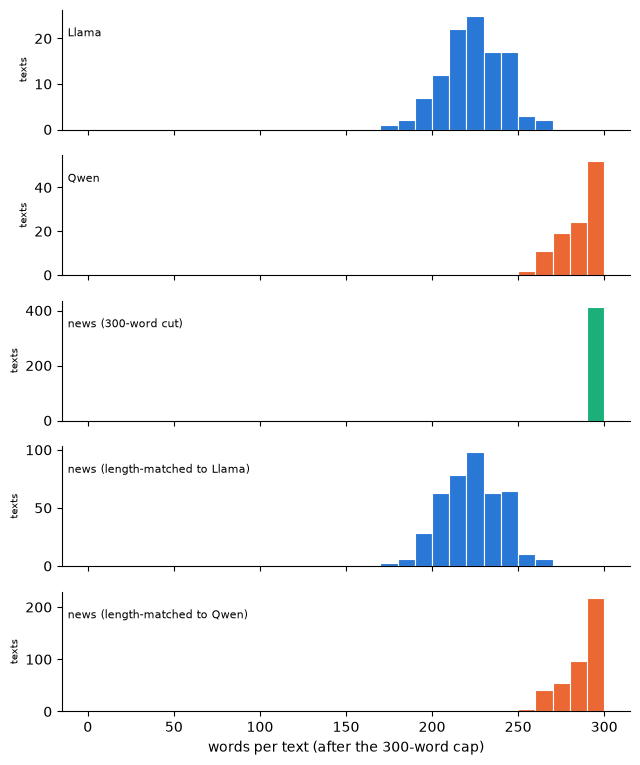

In [4]:
rows = []
for name, d in views.items():
    w = d["n_words"]
    rows.append({"view": name, "n_texts": len(d), "words_mean": w.mean(), "words_median": w.median(), "words_sd": w.std(),
                 "ks_vs_Llama": ks_2samp(w, views["Llama"]["n_words"]).statistic, "ks_vs_Qwen": ks_2samp(w, views["Qwen"]["n_words"]).statistic})
length_table = pd.DataFrame(rows).round(3)
length_table.to_csv(OUT / "length_match_table.csv", index=False)
display(length_table)

fig, axes = plt.subplots(len(views), 1, figsize=(6.5, 1.55 * len(views)), sharex=True)
bins = np.arange(0, 310, 10)
for ax, (name, d) in zip(axes, views.items()):
    key = "Llama" if "Llama" in name else "Qwen" if "Qwen" in name else "news"
    ax.hist(d["n_words"], bins=bins, color=COLOR[key], edgecolor="white", linewidth=0.8)
    ax.set_ylabel("texts", fontsize=7); ax.text(0.01, 0.78, name, transform=ax.transAxes, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes[-1].set_xlabel("words per text (after the 300-word cap)")
fig.tight_layout(); fig.savefig(OUT / "length_histograms.png", dpi=200); plt.show()

## 3. Frame density (a result in its own right)
Share of texts with fewer than K hits, per group: the texts that rarefaction has to exclude. Also hits per 100 words as a separate descriptive table, because density differs between chatbots and news and plain entropy depends on it.

In [5]:
rows = []
for name, d in views.items():
    parts = {name: d} if "news" not in name else {name: d, **{f"{name} | {r}": d[d.region == r] for r in ["US", "UK", "EU", "Other"]}}
    for nm, g in parts.items():
        rows.append({"view": nm, "n_texts": len(g), **{f"share_under_{k}_hits": (g["hits_total"] < k).mean() for k in KS},
                     "hits_mean": g["hits_total"].mean(), "hits_median": g["hits_total"].median(),
                     "hits_per_100w_mean": g["hits_per_100w"].mean(), "hits_per_100w_median": g["hits_per_100w"].median()})
density = pd.DataFrame(rows).round(3)
density.to_csv(OUT / "frame_density.csv", index=False)
density[["view", "n_texts"] + [f"share_under_{k}_hits" for k in KS]]

,view,n_texts,share_under_3_hits,share_under_5_hits,share_under_8_hits
0,Llama,108,0.000,0.000,0.056
1,Qwen,108,0.000,0.000,0.000
2,news (300-word cut),420,0.117,0.257,0.493
3,news (300-word cut) | US,133,0.128,0.271,0.519
4,news (300-word cut) | UK,101,0.069,0.188,0.455
5,news (300-word cut) | EU,82,0.110,0.232,0.427
6,news (300-word cut) | Other,104,0.154,0.327,0.548
7,news (length-matched to Llama),420,0.183,0.386,0.674
8,news (length-matched to Llama) | US,133,0.195,0.414,0.707
9,news (length-matched to Llama) | UK,101,0.129,0.317,0.653


In [6]:
density[["view", "hits_mean", "hits_median", "hits_per_100w_mean", "hits_per_100w_median"]]

,view,hits_mean,hits_median,hits_per_100w_mean,hits_per_100w_median
0,Llama,15.583,16.0,6.961,6.798
1,Qwen,26.352,27.5,9.175,9.360
2,news (300-word cut),8.262,8.0,2.768,2.667
3,news (300-word cut) | US,8.008,7.0,2.682,2.333
4,news (300-word cut) | UK,8.891,8.0,3.004,2.667
5,news (300-word cut) | EU,8.646,8.0,2.885,2.667
6,news (300-word cut) | Other,7.673,7.0,2.558,2.333
7,news (length-matched to Llama),6.217,5.0,2.803,2.449
8,news (length-matched to Llama) | US,5.910,5.0,2.693,2.315
9,news (length-matched to Llama) | UK,6.772,6.0,3.067,2.551


## 4. Rarefied entropy per text
One row per text and K. Saved without any article text.

In [7]:
def add_rarefied(d, ks=KS, reps=REPS, seed=SEED):
    d = d.copy(); r = np.random.default_rng(seed)
    for k in ks:
        d[f"rar{k}"] = [rarefied_entropy(row, k, r, reps) for row in d[HC].to_numpy()]
    d["plugin5"] = [entropy(row, 5) for row in d[HC].to_numpy()]               # plain entropy, texts with >= 5 hits
    return d

scored = {name: add_rarefied(d) for name, d in views.items()}
allrows = pd.concat([d.assign(view=name)[["view", "text_id", "group", "cluster", "n_words", "hits_total", "hits_per_100w", "plugin5"] + [f"rar{k}" for k in KS] + HC]
                     for name, d in scored.items()])
allrows.to_csv(OUT / "rarefied_entropy_per_text.csv", index=False)
print(len(allrows), "rows saved; texts that can be rarefied at K=5:", int(allrows["rar5"].notna().sum()))
# counts only: group means of the entropies are H1 results and stay behind the gate
allrows.groupby("view")[["plugin5", "rar5"]].count()

1476 rows saved; texts that can be rarefied at K=5: 1092


,plugin5,rar5
view,,
Llama,108,108
Qwen,108,108
news (300-word cut),312,312
news (length-matched to Llama),258,258
news (length-matched to Qwen),306,306


## 5. Does entropy still depend on length and hit count?
Spearman correlation of entropy with word count and with hit count, before (plain entropy, texts with at least 5 hits) and after rarefaction (K = 5). After rarefaction the correlation with hit count should be close to zero by construction; the one with word count tells whether anything length-related is left.

In [8]:
rows = []
pools = {"chatbot answers (both)": pd.concat([scored["Llama"], scored["Qwen"]]), "Llama": scored["Llama"], "Qwen": scored["Qwen"],
         "news (300-word cut)": scored["news (300-word cut)"]}
for name, d in pools.items():
    for col, label in [("plugin5", "before (plain entropy)"), ("rar5", "after (rarefied, K=5)")]:
        ok = d.dropna(subset=[col])
        for x, xl in [("n_words", "word count"), ("hits_total", "hit count")]:
            if ok[x].nunique() > 1 and len(ok) > 5:
                rho, p = spearmanr(ok[x], ok[col]); rows.append({"texts": name, "entropy": label, "against": xl, "n": len(ok), "spearman_rho": round(rho, 3)})
corr = pd.DataFrame(rows); corr.to_csv(OUT / "entropy_length_correlations.csv", index=False)
corr.pivot_table(index=["texts", "against"], columns="entropy", values="spearman_rho")

entropy                            after (rarefied, K=5)  \
texts                  against                             
Llama                  hit count                  -0.143   
                       word count                 -0.025   
Qwen                   hit count                  -0.107   
                       word count                 -0.083   
chatbot answers (both) hit count                   0.177   
                       word count                  0.312   
news (300-word cut)    hit count                  -0.123   
                       word count                 -0.056   

entropy                            before (plain entropy)  
texts                  against                             
Llama                  hit count                    0.050  
                       word count                   0.027  
Qwen                   hit count                    0.131  
                       word count                  -0.092  
chatbot answers (both) hit count                    0.465  
                       word count                   0.497  
news (300-word cut)    hit count                    0.122  
                       word count                  -0.080

## 6. H1 machinery (gated)
Group comparison at matched hit counts. Everything below is defined now and **run on real group labels only when `H_TESTS_ENABLED` is True**. Until then it is exercised on label-shuffled data (section 7) so that the code is known to work without anyone looking at real group differences.

- **Main:** texts with at least K hits, rarefied at K, each chatbot against the news length-matched to that chatbot (primary) and against the 300-word news (secondary). Cluster bootstrap intervals; difference = chatbot minus news.
- **Bounds:** texts that cannot be rarefied are put back with an assumed score: (a) the minimum possible entropy, 0; (b) the group median of the scored texts; (c) the maximum possible, log K / log 6, as the stress test (a is favourable to H1 whenever news is the group with excluded texts, c is the adversarial case). The question is whether the sign of the difference survives each assumption.
- **Sensitivity:** the main comparison at K = 3 and K = 8.
- **Pooled:** add up the hits of all texts in a group, draw N hits from the pooled counts (N = the smaller pooled total of the two groups compared), repeat, compare. Every text is used; there is no exclusion.

In [9]:
def cluster_boot_mean(values, clusters, n_boot=2000, seed=SEED):
    """Mean and 95% interval; clusters (question or outlet) are resampled, not texts."""
    v = pd.Series(values).reset_index(drop=True); c = pd.Series(clusters).reset_index(drop=True)
    g = v.groupby(c); sums, cnts = g.sum().to_numpy(), g.count().to_numpy()
    r = np.random.default_rng(seed); idx = r.integers(0, len(sums), (n_boot, len(sums)))
    boot = sums[idx].sum(axis=1) / cnts[idx].sum(axis=1)
    return v.mean(), np.percentile(boot, 2.5), np.percentile(boot, 97.5), boot

def compare(a, b, col, label, n_boot=2000):
    ma, la, ha, ba = cluster_boot_mean(a[col], a["cluster"], n_boot, SEED)
    mb, lb, hb, bb = cluster_boot_mean(b[col], b["cluster"], n_boot, SEED + 1)
    diff = ba - bb
    return {"comparison": label, "n_chatbot": a[col].notna().sum(), "n_news": b[col].notna().sum(),
            "chatbot_mean": ma, "chatbot_lo": la, "chatbot_hi": ha, "news_mean": mb, "news_lo": lb, "news_hi": hb,
            "diff": ma - mb, "diff_lo": np.percentile(diff, 2.5), "diff_hi": np.percentile(diff, 97.5), "direction_chatbot_higher": ma > mb}

def comparisons(sc, k):
    col, rows = f"rar{k}", []
    for m in MODELS:
        for nname in [f"news (length-matched to {m})", "news (300-word cut)"]:
            a, b = sc[m].dropna(subset=[col]), sc[nname].dropna(subset=[col])
            rows.append({"K": k, **compare(a, b, col, f"{m} vs {nname}")})
    return pd.DataFrame(rows)

def bounds(sc, k=MAIN_K):
    col, rows = f"rar{k}", []
    for m in MODELS:
        nname = f"news (length-matched to {m})"
        for rule in ["(a) excluded scored 0 (minimum)", "(b) excluded scored at group median", "(c) excluded scored at maximum"]:
            filled = {}
            for key in (m, nname):
                d = sc[key].copy(); miss = d[col].isna()
                fill = {"a": 0.0, "b": d[col].median(), "c": np.log(k) / np.log(len(FRAMES))}[rule[1]]
                d[col] = d[col].fillna(fill); filled[key] = (d, int(miss.sum()))
            r = compare(filled[m][0], filled[nname][0], col, f"{m} vs {nname}")
            rows.append({"K": k, "rule": rule, "excluded_chatbot": filled[m][1], "excluded_news": filled[nname][1], **r})
    return pd.DataFrame(rows)

def pooled(sc, reps=1000, n_boot=300, seed=SEED):
    rows = []
    for m in MODELS:
        for nname in [f"news (length-matched to {m})", "news (300-word cut)"]:
            A, B = sc[m], sc[nname]
            tot = lambda d: d[HC].sum().to_numpy(int)
            N = int(min(tot(A).sum(), tot(B).sum())); r = np.random.default_rng(seed)
            ea, eb = rarefied_entropy(tot(A), N, r, reps), rarefied_entropy(tot(B), N, r, reps)
            boots = []
            ca = A.groupby("cluster")[HC].sum(); cb = B.groupby("cluster")[HC].sum()
            for _ in range(n_boot):
                pa = ca.iloc[r.integers(0, len(ca), len(ca))].sum().to_numpy(int); pb = cb.iloc[r.integers(0, len(cb), len(cb))].sum().to_numpy(int)
                n = int(min(N, pa.sum(), pb.sum()))
                boots.append(rarefied_entropy(pa, n, r, 50) - rarefied_entropy(pb, n, r, 50))
            rows.append({"comparison": f"{m} vs {nname}", "N_hits_drawn": N, "chatbot_pooled_entropy": ea, "news_pooled_entropy": eb, "diff": ea - eb,
                         "diff_lo": np.percentile(boots, 2.5), "diff_hi": np.percentile(boots, 97.5), "direction_chatbot_higher": ea > eb})
    return pd.DataFrame(rows)

def run_h1(sc, write=True):
    out = {"h1_main": comparisons(sc, MAIN_K), "h1_sensitivity": pd.concat([comparisons(sc, k) for k in (3, 8)], ignore_index=True),
           "h1_bounds": bounds(sc), "h1_pooled": pooled(sc)}
    if write:
        for name, df in out.items(): df.round(4).to_csv(OUT / f"{name}.csv", index=False)
    return out

## 7. Self-test on label-shuffled data
The comparison code is run once with the group labels of all texts **randomly permuted** (chatbot answers and news chunks swapped between sides). The numbers are noise and are never saved; the point is to prove that the code runs, returns the right tables, and that a label-free comparison does not show a systematic gap.

In [10]:
def shuffled_views(seed=7):
    r = np.random.default_rng(seed)
    pool = pd.concat([scored["Llama"], scored["Qwen"], scored["news (300-word cut)"]], ignore_index=True)
    perm = pool.sample(frac=1, random_state=seed).reset_index(drop=True)
    sc = {}
    sc["Llama"] = perm.iloc[:108]; sc["Qwen"] = perm.iloc[108:216]; sc["news (300-word cut)"] = perm.iloc[216:216 + 420]
    sc["news (length-matched to Llama)"] = perm.iloc[216:216 + 420]; sc["news (length-matched to Qwen)"] = perm.iloc[216:216 + 420]
    return sc

fake = run_h1(shuffled_views(), write=False)
for name, df in fake.items():
    assert len(df) > 0, name
print({k: df.shape for k, df in fake.items()})
mean_gap = fake["h1_main"]["diff"].abs().mean()
print("self-test passed: all four tables built on shuffled labels; mean |gap| on shuffled labels =", round(mean_gap, 3), "(should be small)")

{'h1_main': (4, 14), 'h1_sensitivity': (8, 14), 'h1_bounds': (6, 17), 'h1_pooled': (4, 8)}
self-test passed: all four tables built on shuffled labels; mean |gap| on shuffled labels = 0.018 (should be small)


## 8. Run H1 on the real groups (only after sign-off)

In [11]:
if not H_TESTS_ENABLED:
    print("H_TESTS_ENABLED is False: the real H1 comparisons are not computed. Flip the switch after the lexicon is signed off.")
else:
    res = run_h1(scored)
    for name, df in res.items():
        print("\n" + name); display(df.round(3))

H_TESTS_ENABLED is False: the real H1 comparisons are not computed. Flip the switch after the lexicon is signed off.


## Limits to state in the report
- Rarefaction fixes the dependence on hit count but not on *which* terms are common: news and chatbot hits come from different words (see `07_lexicon_signoff.ipynb`).
- At K = 5 the maximum entropy is 0.898, not 1; at K = 3 it is 0.613. Never compare values across different K.
- Texts with fewer than K hits are excluded; frame density (section 3) and the bounds analysis say how much that matters.
- 18 questions give 18 chatbot clusters, so chatbot intervals are wide and the bootstrap has few clusters to draw from.
- Length matching uses each chatbot's own answer lengths; articles shorter than their target keep all their words, so a small length gap can remain (see the length table).